In [41]:
# Project objective and problem definition
print("Customer Churn Prediction using ANN")

Customer Churn Prediction using ANN



## 2. Import Libraries


In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn

## 3. Dataset Collection

In [43]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/kaggle/input/datasets/shiyalkishan01/ibm-telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [44]:
df = pd.read_csv(
    "/kaggle/input/datasets/shiyalkishan01/ibm-telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

print("Dataset loaded successfully!")

print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 4. Exploratory Data Analysis (EDA)

In [45]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 7043
Columns: 21


In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [47]:
df.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,3186-AJIEK,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [48]:
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [49]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0



## 5. Data Preprocessing

Churn distribution

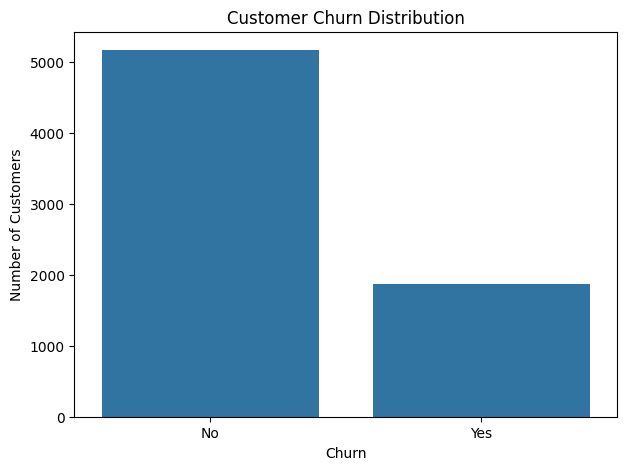

In [50]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

Monthly charges vs churn

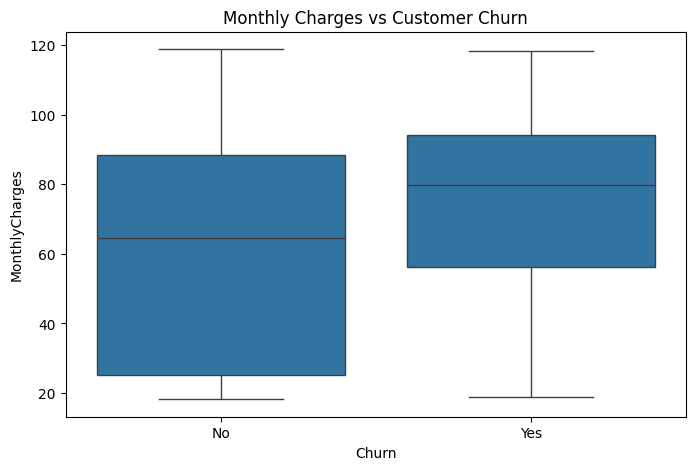

In [51]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Customer Churn")

plt.show()

Tenure vs churn

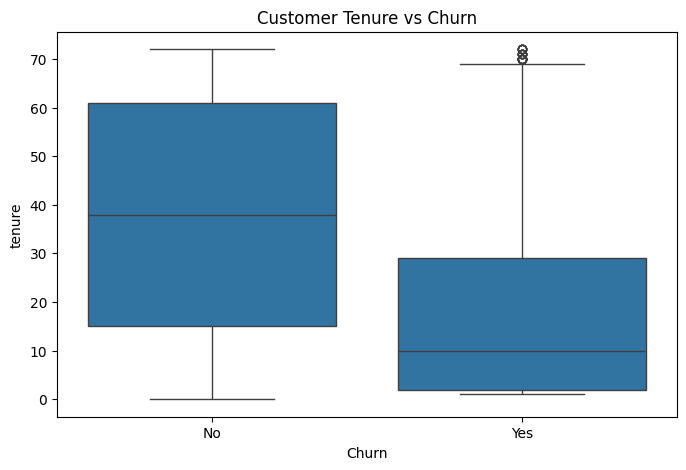

In [52]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure vs Churn")

plt.show()

# Check blank values in TotalCharges

In [53]:
print("Blank TotalCharges:",
      (df["TotalCharges"].str.strip() == "").sum())

print("Data type:", df["TotalCharges"].dtype)

Blank TotalCharges: 11
Data type: object


# Convert TotalCharges into numeric

In [54]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("Missing values after conversion:")
print(df.isnull().sum())

Missing values after conversion:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


# Check missing values

In [55]:
print(df.isnull().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


# Remove rows containing missing values

In [56]:
df = df.dropna()

print("Dataset shape after removing missing values:", df.shape)

print("Remaining missing values:", df.isnull().sum().sum())

Dataset shape after removing missing values: (7032, 21)
Remaining missing values: 0


# Remove customerID

In [57]:
df = df.drop("customerID", axis=1)

print(df.shape)

(7032, 20)


# Separate independent and dependent variables

In [58]:
X = df.drop("Churn", axis=1)

y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7032, 19)
Target shape: (7032,)


In [59]:
y = y.map({
    "No": 0,
    "Yes": 1
})

print(y.value_counts())

Churn
0    5163
1    1869
Name: count, dtype: int64


Split numerical and categorical columns

In [60]:
numerical_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical columns:", numerical_cols)

print("\nCategorical columns:", categorical_cols)

Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


### Train-Test Split

In [65]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(type(X_train))
print(type(X_test))

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.frame.DataFrame'>


### Feature Scaling and One-Hot Encoding

In [66]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from scipy.sparse import issparse

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

# Fit on training data
X_train = preprocessor.fit_transform(X_train)

# Transform testing data
X_test = preprocessor.transform(X_test)

# Convert sparse matrices only when necessary
if issparse(X_train):
    X_train = X_train.toarray()

if issparse(X_test):
    X_test = X_test.toarray()

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (5625, 45)
Testing shape: (1407, 45)


### Converting Data into PyTorch Tensors

In [67]:
# Convert features into float32 tensors

X_train_tensor = torch.tensor(
    X_train,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
)

# Convert targets into float32 tensors

y_train_tensor = torch.tensor(
    y_train.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

y_test_tensor = torch.tensor(
    y_test.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

print("X_train:", X_train_tensor.shape)
print("X_test:", X_test_tensor.shape)

print("y_train:", y_train_tensor.shape)
print("y_test:", y_test_tensor.shape)

X_train: torch.Size([5625, 45])
X_test: torch.Size([1407, 45])
y_train: torch.Size([5625, 1])
y_test: torch.Size([1407, 1])


##  Building the Artificial Neural Network

###  Creating DataLoader

In [68]:
from torch.utils.data import TensorDataset, DataLoader

# Create training dataset
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

# Create testing dataset
test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 176
Testing batches: 44


### Defining ANN Architecture
Creating a feedforward neural network with two hidden layers using PyTorch.

In [69]:
import torch
import torch.nn as nn

# Define ANN architecture

class CustomerChurnANN(nn.Module):

    def __init__(self, input_size):

        super(CustomerChurnANN, self).__init__()

        self.network = nn.Sequential(

            nn.Linear(input_size, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 1)

        )

    def forward(self, x):

        return self.network(x)


# Get number of input features
input_size = X_train_tensor.shape[1]

# Create model
model = CustomerChurnANN(input_size)

print(model)

CustomerChurnANN(
  (network): Sequential(
    (0): Linear(in_features=45, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)


### Loss Function and Optimizer

Using Binary Cross Entropy with Logits as the loss function and Adam as the optimizer.

In [70]:
# Define loss function
criterion = nn.BCEWithLogitsLoss()

# Define optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


### Training the ANN

Training the neural network using forward propagation,
loss calculation and backpropagation.

In [71]:
# Number of training epochs
epochs = 50

# Training loop
for epoch in range(epochs):

    model.train()

    total_loss = 0

    for inputs, targets in train_loader:

        # Forward propagation
        outputs = model(inputs)

        # Calculate loss
        loss = criterion(outputs, targets)

        # Clear previous gradients
        optimizer.zero_grad()

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    if (epoch + 1) % 5 == 0:

        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {avg_loss:.4f}"
        )

Epoch [5/50], Loss: 0.4147
Epoch [10/50], Loss: 0.4085
Epoch [15/50], Loss: 0.4042
Epoch [20/50], Loss: 0.3980
Epoch [25/50], Loss: 0.3934
Epoch [30/50], Loss: 0.3892
Epoch [35/50], Loss: 0.3857
Epoch [40/50], Loss: 0.3822
Epoch [45/50], Loss: 0.3763
Epoch [50/50], Loss: 0.3724


### Model Evaluation

Evaluating the trained ANN on unseen testing data using
accuracy, precision, recall, F1-score and ROC-AUC.

In [72]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

model.eval()

all_predictions = []
all_probabilities = []
all_targets = []

with torch.no_grad():

    for inputs, targets in test_loader:

        logits = model(inputs)

        probabilities = torch.sigmoid(logits)

        predictions = (probabilities >= 0.5).float()

        all_predictions.extend(predictions.cpu().numpy().flatten())
        all_probabilities.extend(probabilities.cpu().numpy().flatten())
        all_targets.extend(targets.cpu().numpy().flatten())


# Calculate evaluation metrics

print("Accuracy:", accuracy_score(all_targets, all_predictions))

print("Precision:", precision_score(all_targets, all_predictions))

print("Recall:", recall_score(all_targets, all_predictions))

print("F1 Score:", f1_score(all_targets, all_predictions))

print("ROC-AUC:", roc_auc_score(all_targets, all_probabilities))

print("\nClassification Report:")
print(classification_report(all_targets, all_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(all_targets, all_predictions))

Accuracy: 0.7917555081734187
Precision: 0.6310679611650486
Recall: 0.5213903743315508
F1 Score: 0.5710102489019033
ROC-AUC: 0.8258058921887862

Classification Report:
              precision    recall  f1-score   support

         0.0       0.84      0.89      0.86      1033
         1.0       0.63      0.52      0.57       374

    accuracy                           0.79      1407
   macro avg       0.73      0.71      0.72      1407
weighted avg       0.78      0.79      0.79      1407


Confusion Matrix:
[[919 114]
 [179 195]]


In [73]:
torch.save(
    model.state_dict(),
    "ann_customer_churn.pth"
)

print("Model saved successfully!")

Model saved successfully!
